In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [3]:
observables1 = ['pt','b','w','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','ws','y1s','y2s','phi1s','phi2s','nefs']

In [4]:
df_allreco = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all050124_rc_hadcorr05_notrueptcons.root', "MatchedTree"),\
              'pts>15 and bs!=-9 and w<1')

In [5]:
distance1 = []
distance2 = []
for i in range(0,df_allreco.shape[0]):
    phi1small = min(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi1large = max(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi2small = min(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    phi2large = max(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_allreco.iloc[i]['y1']-df_allreco.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_allreco.iloc[i]['y2']-df_allreco.iloc[i]['y2s'])**2))
df_allreco['distance1'] = distance1
df_allreco['distance2'] = distance2

Process PYTHIA6+GEANT

In [6]:
df_match = applyCut(df_allreco, 'pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02')
df_allfake = applyCut(df_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')

In [7]:
print(df_match.shape[0], df_allfake.shape[0])

2670179 1498387


In [8]:
print(np.unique(df_match['bs']))

[-1  1]


In [9]:
df_allreco_pts_array = [ df_allreco[(df_allreco.pts>15) & (df_allreco.pts<20)],\
                       df_allreco[(df_allreco.pts>20) & (df_allreco.pts<25)],\
                       df_allreco[(df_allreco.pts>25) & (df_allreco.pts<30)],\
                       df_allreco[(df_allreco.pts>30) & (df_allreco.pts<40)],\
                       df_allreco[(df_allreco.pts>40) & (df_allreco.pts<60)]]

df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)] ]

df_allfake_pts_array = [ df_allfake[(df_allfake.pts>15) & (df_allfake.pts<20)],\
                       df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25)],\
                       df_allfake[(df_allfake.pts>25) & (df_allfake.pts<30)],\
                       df_allfake[(df_allfake.pts>30) & (df_allfake.pts<40)],\
                       df_allfake[(df_allfake.pts>40) & (df_allfake.pts<60)]  ]

In [10]:
rc_allreco_bs_vs_pts_array = []
rc_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df_allreco_pts_array)):
    rc_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[0])
    rc_err_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[1])

In [11]:
plt.rcParams['font.size'] = 12

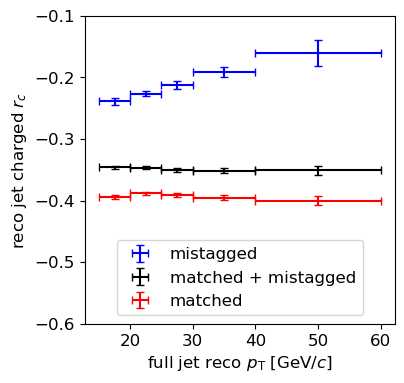

In [12]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allfake_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allfake_bs_vs_pts_array, capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allreco_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allreco_bs_vs_pts_array, capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco jet charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')

In [13]:
rc_allfake_bs_vs_pts_array

[-0.23872884599002328,
 -0.22626296932663054,
 -0.2128714900712753,
 -0.1917938008121452,
 -0.1601026677203986]

In [14]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [15]:
b_fake_array = []
for i in range(0,5):
    df_fake_pts = df_allfake_pts_array[i]
    y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_pts['ws'], density=True)
    b_fake_array.append(y_fake_rec/sum(y_fake_rec))

In [16]:
b_fake_array

[array([0.61936442, 0.38063558]),
 array([0.61313148, 0.38686852]),
 array([0.60643575, 0.39356425]),
 array([0.5958969, 0.4041031]),
 array([0.58005133, 0.41994867])]

In [17]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)]  ]

In [18]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[1])

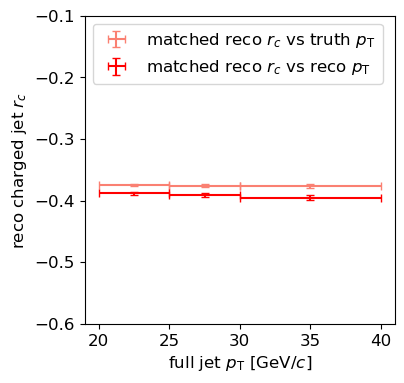

In [19]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:-1], capsize=3, color='salmon', ls='none', label='matched reco $r_c$ vs truth $p_{\mathrm{T}}$')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='r', ls='none', label='matched reco $r_c$ vs reco $p_{\mathrm{T}}$')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='upper left')

In [20]:
b_match_array = []
for i in range(0,5):
    df_match_pts = df_match_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_match_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pts['ws'], density=True)
    b_match_array.append(y_reco/sum(y_reco))
    print(y_reco/sum(y_reco))

[0.69695793 0.30304207]
[0.69400819 0.30599181]
[0.6954742 0.3045258]
[0.69773917 0.30226083]
[0.70000985 0.29999015]


In [21]:
binedges=[5,10,15,20,25,30,40,60]
match_fake, x = np.histogram(df_allreco['pts'], bins=binedges, weights=df_allreco['ws'])
match, _ = np.histogram(df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['pts'], bins=binedges, weights=df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['ws'])
eff4 = match/match_fake

/tmp/ipykernel_2754457/4101531506.py:4: RuntimeWarning: invalid value encountered in divide
  eff4 = match/match_fake


In [22]:
fake_rate_array = np.ones(5)-eff4[2:7]
fake_rate_array

array([0.30791236, 0.25663592, 0.2303956 , 0.21554604, 0.20459887])

Process data

In [23]:
observables1 = ['pt','b']
file = uproot.open('/gpfs/gibbs/project/havener/ys668/rc/data0613_chargedrc.root')
tree = file["ResultTree"].arrays(observables1, library='np')
df_data = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b'])))), columns=["pts","bs"])
df_data = applyCut(df_data, 'pts>15 and bs!=-9 and bs!=0')

In [24]:
df_data_pts_array = [ df_data[(df_data.pts>15) & (df_data.pts<20)],\
                       df_data[(df_data.pts>20) & (df_data.pts<25)],\
                       df_data[(df_data.pts>25) & (df_data.pts<30)],\
                       df_data[(df_data.pts>30) & (df_data.pts<40)],\
                       df_data[(df_data.pts>40) & (df_data.pts<60)]  ]

In [25]:
def getRcAndErrAndN(df, ob):
    if (ob == 'bs'):
        nos = df[df.bs==-1].shape[0]
        nss = df[df.bs==+1].shape[0]
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n = nss+nos
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err, n

In [26]:
rc_data_bs_vs_pts_array = []
rc_err_data_bs_vs_pts_array = []
for i in range(0, len(df_data_pts_array)):
    rc_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[0])
    rc_err_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[1])

In [27]:
b_data_array = []
for i in range(0,5):
    df_data_pts = df_data_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_data_pts['bs'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))
    b_data_array.append(y_reco)

# 1. Mistagged subtraction

In [28]:
def getMatchedCountAndErr(data, fake_rate, fake_dist):
    corrected = data - sum(data) * fake_rate * fake_dist
    err = np.sqrt(corrected)
    return corrected, err

In [29]:
b_fakesubtracted_array = []
b_fakesubtractederr_array = []
rc1_array = []
rc1_err_array = []
for i in range(0,5):
    print(i)
    print(b_data_array[i])
    #print(getRc(data_array[i]))
    b_fakesubtracted, b_fakesubtractederr = getMatchedCountAndErr(b_data_array[i], fake_rate_array[i], b_fake_array[i])
    b_fakesubtracted_array.append(b_fakesubtracted)
    b_fakesubtractederr_array.append(b_fakesubtractederr)
    print(b_fakesubtracted)
    print(b_fakesubtractederr)
    nos = b_fakesubtracted[0]
    nss = b_fakesubtracted[1]
    n = nos + nss
    p = nss / n
    rc1 = (nss-nos) / (nss+nos)
    rc1_array.append(rc1)
    rc1_err_array.append( 2*np.sqrt(p*(1-p)/n) )

0
[337314. 178144.]
[239011.02527894 117731.08618858]
[488.88753848 343.1196383 ]
1
[72379. 38554.]
[54923.51906218 27540.08836144]
[234.35767336 165.95206646]
2
[16450.  8688.]
[12937.71541809  6408.59995471]
[113.74407861  80.05373167]
3
[4758. 2573.]
[3816.38276821 1934.44920079]
[61.77687891 43.98237375]
4
[334. 153.]
[276.20388908 111.15646259]
[16.61938293 10.54307652]


In [30]:
print(rc_data_bs_vs_pts_array)

[-0.3087933449476, -0.3049137767841851, -0.30877555891479036, -0.2980493793479744, -0.37166324435318276]


Text(20, -0.2, '$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

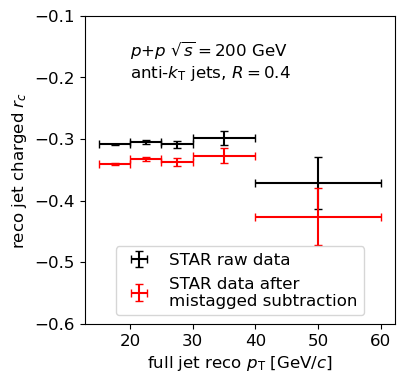

In [31]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_data_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_data_bs_vs_pts_array, capsize=3, color='k', ls='none', label='STAR raw data')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='STAR data after\nmistagged subtraction')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco jet charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.2, '$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

# 2. $p_T$ correction

In [32]:
reweight_array = []
for i in range(0,5):
    reweight = (b_fakesubtracted_array[i]/sum(b_fakesubtracted_array[i]))/(b_match_array[i]/sum(b_match_array[i]))
    reweight_array.append(reweight)

In [33]:
reweight_array

[array([0.96129568, 1.08901498]),
 array([0.95969101, 1.09142325]),
 array([0.96156425, 1.08777934]),
 array([0.95110429, 1.11287089]),
 array([1.01861595, 0.95656076])]

([], [])

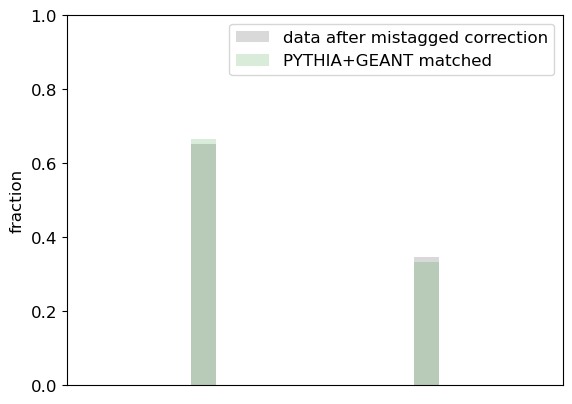

In [34]:
x = np.array([-0.5, 0.5])
plt.hist(x, weights=b_data_array[1]/sum(b_data_array[1]), color='k', alpha=0.15, label='data after mistagged correction')
plt.hist(x, weights=b_fakesubtracted_array[1]/sum(b_fakesubtracted_array[1]), ls='none', color='g', alpha=0.15, label='PYTHIA+GEANT matched')
#plt.errorbar(x+np.array([0.05,-0.05]), b_data_array[1][0]/sum(b_data_array[1]), yerr=y1err_array[0]/sum(b_data_array[1]), capsize=3, color='k', ls='none')
#plt.errorbar(x+np.array([0.05,-0.05]), b_fakesubtracted_array[1][0]/sum(b_fakesubtracted_array[1]), yerr=y1err_pythia_array[0]/sum(b_fakesubtracted_array[1]), capsize=3, color='g', ls='none')
plt.legend(fontsize=12)
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-1,1)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

Reweight PYTHIA6+GEANT

In [35]:
r = []
for i in range(0, df_match.shape[0]):
    if (df_match.iloc[i]['pts'] > 15 and df_match.iloc[i]['pts'] < 20):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[0][0])
        else:
            r.append(reweight_array[0][1])
    elif (df_match.iloc[i]['pts'] > 20 and df_match.iloc[i]['pts'] < 25):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[1][0])
        else:
            r.append(reweight_array[1][1])
    elif (df_match.iloc[i]['pts'] > 25 and df_match.iloc[i]['pts'] < 30):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[2][0])
        else:
            r.append(reweight_array[2][1])
    elif (df_match.iloc[i]['pts'] > 30 and df_match.iloc[i]['pts'] < 40):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[3][0])
        else:
            r.append(reweight_array[3][1])
    elif (df_match.iloc[i]['pts'] > 40 and df_match.iloc[i]['pts'] < 60):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[4][0])
        else:
            r.append(reweight_array[4][1])
    else:
        r.append(1)
        print("anomaly reco pT:", df_match.iloc[i]['pts'])
df_match['r'] = r #

anomaly reco pT: 68.96617247169604
anomaly reco pT: 60.153276062896694
anomaly reco pT: 62.853705443277754
anomaly reco pT: 62.96298659444578
anomaly reco pT: 60.83264616046272
anomaly reco pT: 60.31309896383466
anomaly reco pT: 60.91734178460715
anomaly reco pT: 60.481917097035925
anomaly reco pT: 66.103717780847
anomaly reco pT: 60.89421353610575
anomaly reco pT: 65.35667922469173
anomaly reco pT: 64.47875207921092
anomaly reco pT: 60.11131849040349
anomaly reco pT: 60.26115171262982
anomaly reco pT: 60.21434194892271
anomaly reco pT: 62.55584839791908
anomaly reco pT: 60.27780299483247
anomaly reco pT: 61.03197986884235
anomaly reco pT: 60.25483540234041
anomaly reco pT: 63.99508646678217
anomaly reco pT: 62.139164961369985
anomaly reco pT: 61.56890722000404
anomaly reco pT: 62.01326141868726
anomaly reco pT: 60.8697641572812
anomaly reco pT: 64.23631221912824
anomaly reco pT: 63.19369788337173
anomaly reco pT: 60.96653998630141
anomaly reco pT: 61.64508511587138
anomaly reco pT: 60

anomaly reco pT: 60.536596117217194
anomaly reco pT: 60.90737478794605
anomaly reco pT: 61.645654748590204
anomaly reco pT: 60.02370267400634
anomaly reco pT: 60.95367327969172
anomaly reco pT: 62.499193375458354
anomaly reco pT: 60.945626934831964
anomaly reco pT: 60.74067577434635
anomaly reco pT: 66.88495056985785
anomaly reco pT: 60.856769132346706
anomaly reco pT: 70.62264114647229
anomaly reco pT: 63.71397233021338
anomaly reco pT: 60.06181581868947
anomaly reco pT: 61.723594307211975
anomaly reco pT: 63.95246802002375
anomaly reco pT: 67.8581446933685
anomaly reco pT: 62.37163925475065
anomaly reco pT: 61.01979148407348
anomaly reco pT: 62.63471733037758
anomaly reco pT: 61.144115936189955
anomaly reco pT: 61.2110441827732
anomaly reco pT: 63.099376119447996
anomaly reco pT: 60.72284419784104
anomaly reco pT: 60.659634114539244
anomaly reco pT: 60.06686978750823
anomaly reco pT: 61.42961381695643
anomaly reco pT: 60.40795934028826
anomaly reco pT: 60.68433897369299
anomaly reco 

anomaly reco pT: 61.03492817022248
anomaly reco pT: 60.47804338009482
anomaly reco pT: 60.49268294026377
anomaly reco pT: 62.26187500889052
anomaly reco pT: 61.194513791768124
anomaly reco pT: 60.635226292733975
anomaly reco pT: 65.11959199973253
anomaly reco pT: 62.268597123403346
anomaly reco pT: 61.42498537876831
anomaly reco pT: 63.200002514838935
anomaly reco pT: 62.39269936553728
anomaly reco pT: 60.152754666504634
anomaly reco pT: 63.594963547284266
anomaly reco pT: 63.877322520254616
anomaly reco pT: 62.173479717802685
anomaly reco pT: 62.423084934365974
anomaly reco pT: 61.790378264427254
anomaly reco pT: 60.355440329212726
anomaly reco pT: 61.044594050012684
anomaly reco pT: 64.1822044337918
anomaly reco pT: 62.25934406797988
anomaly reco pT: 60.30630967921048
anomaly reco pT: 61.668104356262795
anomaly reco pT: 62.77769411151896
anomaly reco pT: 61.685289906527885
anomaly reco pT: 63.22484035674715
anomaly reco pT: 63.46598096489497
anomaly reco pT: 61.535248132418374
anomal

anomaly reco pT: 61.09184133665264
anomaly reco pT: 62.98010536481952
anomaly reco pT: 68.47871974807116
anomaly reco pT: 60.55302597287356
anomaly reco pT: 61.41575387791292
anomaly reco pT: 61.346287175305214
anomaly reco pT: 71.06317213094131
anomaly reco pT: 61.690192886595476
anomaly reco pT: 60.85015704702516
anomaly reco pT: 60.12938478622802
anomaly reco pT: 62.66671837648719
anomaly reco pT: 60.40415258649595
anomaly reco pT: 65.6121584077198
anomaly reco pT: 64.4759635101016
anomaly reco pT: 60.21342365031361
anomaly reco pT: 61.076666120325
anomaly reco pT: 60.47492847863472
anomaly reco pT: 60.2406912558355
anomaly reco pT: 60.700066607063796
anomaly reco pT: 64.35276651594903
anomaly reco pT: 62.00414824509995
anomaly reco pT: 65.14152590797455
anomaly reco pT: 60.46591482731075
anomaly reco pT: 69.25773460277277
anomaly reco pT: 63.234442366498655
anomaly reco pT: 65.00134427243431
anomaly reco pT: 64.05987214555824
anomaly reco pT: 61.7646391122221
anomaly reco pT: 66.10

anomaly reco pT: 62.852232385121965
anomaly reco pT: 61.37535295198051
anomaly reco pT: 61.7756374961377
anomaly reco pT: 60.626293563725305
anomaly reco pT: 63.49412634070907
anomaly reco pT: 70.5174880533174
anomaly reco pT: 64.89264083034624
anomaly reco pT: 62.047380805760184
anomaly reco pT: 64.11799735674268
anomaly reco pT: 71.30840532486586
anomaly reco pT: 60.56772574329641
anomaly reco pT: 62.04533335666836
anomaly reco pT: 61.46443570335763
anomaly reco pT: 67.23187474029625
anomaly reco pT: 66.25499459275909
anomaly reco pT: 61.87475157542629
anomaly reco pT: 60.65666211068506
anomaly reco pT: 60.866841954789045
anomaly reco pT: 64.47243708898606
anomaly reco pT: 62.02669746410887
anomaly reco pT: 61.77017138790346
anomaly reco pT: 66.96147501844648
anomaly reco pT: 65.25033525577705
anomaly reco pT: 61.76350377269977
anomaly reco pT: 67.3438977702418
anomaly reco pT: 61.908655086473516
anomaly reco pT: 67.91261516206957
anomaly reco pT: 60.86234980746313
anomaly reco pT: 6

anomaly reco pT: 61.13518478631527
anomaly reco pT: 63.77901688307959
anomaly reco pT: 64.42551408474712
anomaly reco pT: 60.96483102318763
anomaly reco pT: 63.10535819901101
anomaly reco pT: 62.276514899799906
anomaly reco pT: 60.61298014218606
anomaly reco pT: 65.14922986425985
anomaly reco pT: 63.5306159373154
anomaly reco pT: 62.45668089267042
anomaly reco pT: 62.37262846388972
anomaly reco pT: 61.65529398561406
anomaly reco pT: 64.4309918174317
anomaly reco pT: 60.36498068621582
anomaly reco pT: 66.98600402632061
anomaly reco pT: 64.5760594842683
anomaly reco pT: 61.300834918334466
anomaly reco pT: 65.5376321168521
anomaly reco pT: 62.21497274200575
anomaly reco pT: 61.81329662655794
anomaly reco pT: 62.321271143746195
anomaly reco pT: 66.29915248855168
anomaly reco pT: 61.1925411977952
anomaly reco pT: 72.20791752882631
anomaly reco pT: 62.09564203628626
anomaly reco pT: 67.19562431302408
anomaly reco pT: 64.71157913176886
anomaly reco pT: 65.24157857482821
anomaly reco pT: 60.12

... (59 outputs left out)

anomaly reco pT: 64.55601990491277
anomaly reco pT: 63.04310795454887
anomaly reco pT: 66.07781136080767
anomaly reco pT: 62.493576538020534
anomaly reco pT: 68.07647864434605
anomaly reco pT: 62.63598309561028
anomaly reco pT: 60.01134314313232
anomaly reco pT: 61.92407235687211
anomaly reco pT: 69.14406068938273
anomaly reco pT: 67.38643190980758
anomaly reco pT: 64.7834240014963
anomaly reco pT: 65.09531211903634
anomaly reco pT: 71.85053179267702
anomaly reco pT: 60.33627573030803
anomaly reco pT: 61.676575516351555
anomaly reco pT: 60.99310395231298
anomaly reco pT: 65.72734980654091
anomaly reco pT: 60.08689297288352
anomaly reco pT: 60.00829596619937
anomaly reco pT: 69.12911852297967
anomaly reco pT: 67.80551097083507
anomaly reco pT: 60.851533769023504
anomaly reco pT: 67.63121574107147
anomaly reco pT: 61.067497975803484
anomaly reco pT: 62.60893104600202
anomaly reco pT: 60.097973422004735
anomaly reco pT: 61.82860497424666
anomaly reco pT: 69.83262766389413
anomaly reco pT:

anomaly reco pT: 69.1618255253066
anomaly reco pT: 61.56708947013018
anomaly reco pT: 66.65835778943453
anomaly reco pT: 64.63915399961103
anomaly reco pT: 65.7929565225058
anomaly reco pT: 61.42561900355657
anomaly reco pT: 64.41040992735634
anomaly reco pT: 62.72305902639425
anomaly reco pT: 65.49422360739337
anomaly reco pT: 61.5014723980058
anomaly reco pT: 60.274249788939414
anomaly reco pT: 60.98634806629355
anomaly reco pT: 67.22729453988428
anomaly reco pT: 60.32858078889216
anomaly reco pT: 62.31850466206026
anomaly reco pT: 60.04119196752329
anomaly reco pT: 65.24998237953515
anomaly reco pT: 64.47727309036974
anomaly reco pT: 64.62206824734714
anomaly reco pT: 60.46656574446182
anomaly reco pT: 64.67141406461896
anomaly reco pT: 61.51246698620465
anomaly reco pT: 61.901090291712286
anomaly reco pT: 65.63502853225404
anomaly reco pT: 60.04128229501734
anomaly reco pT: 63.60277263479115
anomaly reco pT: 62.20426071842436
anomaly reco pT: 61.301141308150505
anomaly reco pT: 66.

anomaly reco pT: 61.265104574872765
anomaly reco pT: 65.08692239914836
anomaly reco pT: 67.37925468465733
anomaly reco pT: 61.06824480595416
anomaly reco pT: 62.56054850143328
anomaly reco pT: 62.50224606829711
anomaly reco pT: 70.26740093300802
anomaly reco pT: 66.20092514738076
anomaly reco pT: 65.07132415424365
anomaly reco pT: 61.04575363136066
anomaly reco pT: 60.85134140172118
anomaly reco pT: 60.64645607130968
anomaly reco pT: 60.59886547106656
anomaly reco pT: 64.28452030971079
anomaly reco pT: 66.24302137417556
anomaly reco pT: 63.31666433712641
anomaly reco pT: 60.31594807807693
anomaly reco pT: 74.20912081682981
anomaly reco pT: 62.187552053722435
anomaly reco pT: 62.24541150044338
anomaly reco pT: 64.94444418360251
anomaly reco pT: 61.84169774994591
anomaly reco pT: 60.02159703779086
anomaly reco pT: 74.06870213340329
anomaly reco pT: 66.86918989091154
anomaly reco pT: 60.965346787368674
anomaly reco pT: 62.54236962694168
anomaly reco pT: 61.46986896792181
anomaly reco pT: 

/tmp/ipykernel_2754457/3883675663.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_match['r'] = r #


In [36]:
def getRcAndErrNew(df, ob):
    if (ob == 'b'):
        nos = sum(np.array(df[df.b==-1]['w'])* np.array(df[df.b==-1]['r']))
        nss = sum(np.array(df[df.b==+1]['w'])* np.array(df[df.b==1]['r']))
    elif (ob == 'b_ch'):
        nos = sum(np.array(df[df.b_ch==-1]['w'])* np.array(df[df.b_ch==-1]['r']))
        nss = sum(np.array(df[df.b_ch==+1]['w'])* np.array(df[df.b_ch==1]['r']))
    elif (ob == 'bs'):
        nos = sum(np.array(df[df.bs==-1]['ws'])* np.array(df[df.bs==-1]['r']))
        nss = sum(np.array(df[df.bs==+1]['ws'])* np.array(df[df.bs==1]['r']))
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    #variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w']) * np.array(df[df.w == w_array[i]]['r']))
        elif (ob == 'b_ch'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w'] * df[df.w == w_array[i]]['r']))         
        elif (ob == 'bs'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['ws'] * df[df.w == w_array[i]]['r']))
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        #print(variance)
        #variance_array_test.append(variance)
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    #print(variance_array_test)
    rc_err = 2*np.sqrt(sum(err2_array))
    #print(n)
    return rc, rc_err

In [37]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)] ]
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)]  ]

In [38]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[1])
rc_match_bs_vs_pts_array_rw = []
rc_err_match_bs_vs_pts_array_rw = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array_rw.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array_rw.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[1])

Check that the reweighted embedding is the same as data

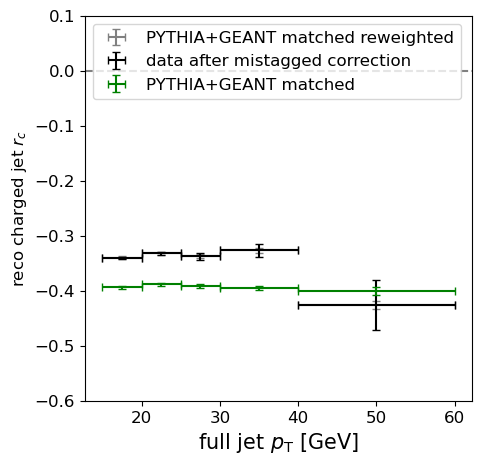

In [46]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array_rw, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array_rw, capsize=3, color='grey', ls='none', label='PYTHIA+GEANT matched reweighted')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='k', ls='none', label='data after mistagged correction')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='g', ls='none', label='PYTHIA+GEANT matched')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [39]:
print(rc_match_bs_vs_pts_array_rw)

[-0.3399653003926211, -0.3320668541664727, -0.33748625190670567, -0.327245445108722, -0.4260823953214168]


Text(20, -0.25, 'STAR data\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

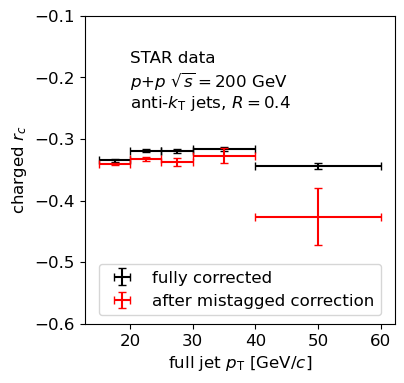

In [40]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='k', ls='none', label='fully corrected')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='after mistagged correction')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.25, 'STAR data\n$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

Plot result

(-0.6, 0.1)

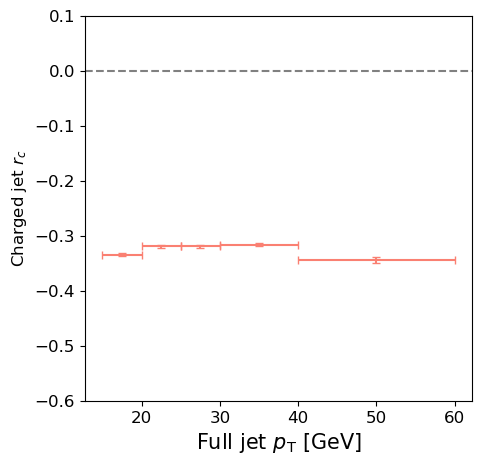

In [41]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='salmon', ls='none', label='sample 1 corrected')
#plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:], capsize=3, color='r', ls='none', label='sample 1 corrected')
plt.xlabel('Full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('Charged jet $r_c$')
plt.ylim(-0.6,0.1)
#plt.legend(loc='upper left', fontsize=15)

In [42]:
rc_match_bs_vs_pt_array

[-0.33492386693534776,
 -0.31918113493024397,
 -0.3195132393077672,
 -0.3160110661784078,
 -0.34352976265183055]

In [43]:
rc_err_match_bs_vs_pt_array

[0.002833652569203003,
 0.002256630010509126,
 0.0028190747532078585,
 0.0035040256523948413,
 0.005223849610531229]